# Parse Debug: Packaged SCHP LIP -> CP-VTON+ masks

This notebook stops before VTON. It validates the raw human parsing and the masks CP-VTON+ derives from it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from tryon_parse_hf import (
    LIP_LABELS,
    PARSE_CLOTH_LABELS,
    PHEAD_TOM_LABELS,
    labels_to_mask,
    parse_human_packaged,
)

PERSON_PATH = Path('photo_full.png')
OUT_DIR = Path('backend/output')
OUT_DIR.mkdir(parents=True, exist_ok=True)
FINE_SIZE = (192, 256)

person = Image.open(PERSON_PATH).convert('RGB')
print('person:', person.size)
print('model dir exists:', Path('models/schp_hf/model.safetensors').exists())

person: (550, 1256)
model dir exists: True


In [2]:
LIP_COLORS = np.array([
    [0, 0, 0],       # 0 Background
    [128, 0, 0],     # 1 Hat
    [255, 0, 0],     # 2 Hair
    [0, 85, 0],      # 3 Glove
    [170, 0, 51],    # 4 Sunglasses
    [255, 85, 0],    # 5 Upper-clothes
    [0, 0, 85],      # 6 Dress
    [0, 119, 221],   # 7 Coat
    [85, 85, 0],     # 8 Socks
    [0, 85, 85],     # 9 Pants
    [85, 51, 0],     # 10 Jumpsuits
    [52, 86, 128],   # 11 Scarf
    [0, 128, 0],     # 12 Skirt
    [0, 0, 255],     # 13 Face
    [51, 170, 221],  # 14 Left-arm
    [0, 255, 255],   # 15 Right-arm
    [85, 255, 170],  # 16 Left-leg
    [170, 255, 85],  # 17 Right-leg
    [255, 255, 0],   # 18 Left-shoe
    [255, 170, 0],   # 19 Right-shoe
], dtype=np.uint8)

def colorize(labels):
    return LIP_COLORS[np.clip(labels, 0, len(LIP_COLORS) - 1)]

def masked_rgb(image, mask):
    rgb = np.array(image.resize((mask.shape[1], mask.shape[0]), Image.Resampling.BILINEAR))
    out = np.zeros_like(rgb)
    out[mask > 0] = rgb[mask > 0]
    return out

def show(items, cols=4, figsize=(14, 8)):
    rows = (len(items) + cols - 1) // cols
    plt.figure(figsize=figsize)
    for i, (title, img) in enumerate(items, 1):
        plt.subplot(rows, cols, i)
        if img.ndim == 2:
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## Run packaged FP32 SCHP

In [3]:
labels_full = parse_human_packaged(person, target_size=person.size, device='cpu')
labels_vton = parse_human_packaged(person, target_size=FINE_SIZE, device='cpu')

print('labels_full:', labels_full.shape, labels_full.dtype, labels_full.min(), labels_full.max())
print('labels_vton:', labels_vton.shape, labels_vton.dtype, labels_vton.min(), labels_vton.max())

unique, counts = np.unique(labels_vton, return_counts=True)
for label, count in zip(unique, counts):
    print(f'{label:2d} {LIP_LABELS[int(label)]:14s} {int(count):6d}')

labels_full: (1256, 550) uint8 0 18
labels_vton: (256, 192) uint8 0 18
 0 Background      31768
 1 Hat               351
 3 Glove              21
 5 Upper-clothes    5585
 8 Socks             132
 9 Pants            9361
13 Face              870
14 Left-arm          885
15 Right-arm          35
18 Left-shoe         144


## CP-VTON+ derived masks

parse_debug.ipynb:cell-2:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


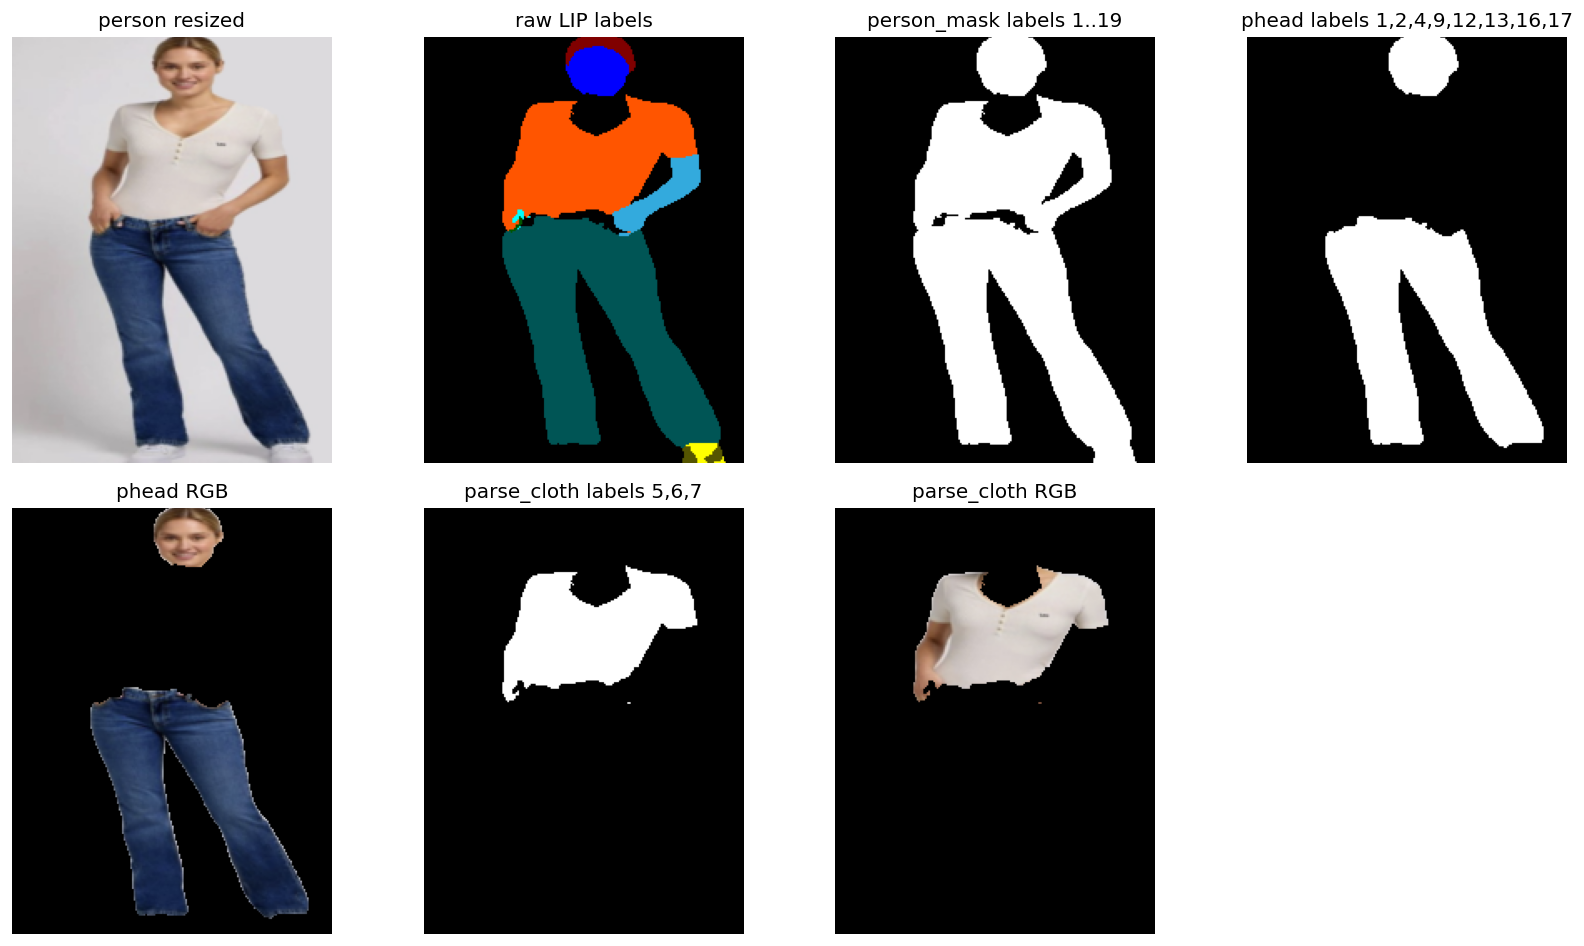

In [4]:
person_mask = labels_to_mask(labels_vton, set(range(1, 20)))
phead = labels_to_mask(labels_vton, PHEAD_TOM_LABELS)
parse_cloth_mask = labels_to_mask(labels_vton, PARSE_CLOTH_LABELS)

person_small = person.resize(FINE_SIZE, Image.Resampling.BILINEAR)
parse_cloth_rgb = masked_rgb(person_small, parse_cloth_mask)
phead_rgb = masked_rgb(person_small, phead)

Image.fromarray(colorize(labels_vton)).save(OUT_DIR / 'parse_debug_lip_labels.png')
Image.fromarray(person_mask).save(OUT_DIR / 'parse_debug_person_mask.png')
Image.fromarray(phead).save(OUT_DIR / 'parse_debug_phead_mask.png')
Image.fromarray(parse_cloth_mask).save(OUT_DIR / 'parse_debug_parse_cloth_mask.png')
Image.fromarray(parse_cloth_rgb).save(OUT_DIR / 'parse_debug_parse_cloth_rgb.png')
Image.fromarray(phead_rgb).save(OUT_DIR / 'parse_debug_phead_rgb.png')

show([
    ('person resized', np.array(person_small)),
    ('raw LIP labels', colorize(labels_vton)),
    ('person_mask labels 1..19', person_mask),
    ('phead labels 1,2,4,9,12,13,16,17', phead),
    ('phead RGB', phead_rgb),
    ('parse_cloth labels 5,6,7', parse_cloth_mask),
    ('parse_cloth RGB', parse_cloth_rgb),
], cols=4, figsize=(14, 8))